Saved figure successfully


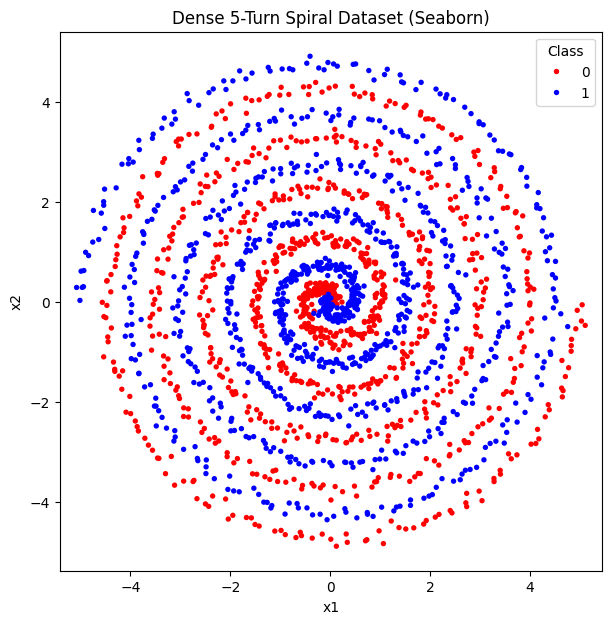

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

def generate_dense_spiral(n_samples_per_class=1000, n_turns=5.0, noise=0.08):
    np.random.seed(42)
    theta = np.linspace(0, n_turns * 2 * np.pi, n_samples_per_class)
    r = theta / (2 * np.pi)

    # Class 0 spiral
    d1x = r * np.cos(theta) + np.random.randn(n_samples_per_class) * noise
    d1y = r * np.sin(theta) + np.random.randn(n_samples_per_class) * noise

    # Class 1 spiral
    d2x = -r * np.cos(theta) + np.random.randn(n_samples_per_class) * noise
    d2y = -r * np.sin(theta) + np.random.randn(n_samples_per_class) * noise

    X = np.vstack((np.hstack((d1x, d2x)), np.hstack((d1y, d2y)))).T
    y = np.hstack((np.zeros(n_samples_per_class), np.ones(n_samples_per_class)))

    return X, y

X, y = generate_dense_spiral(n_samples_per_class=1000, n_turns=5.0, noise=0.08)

# Convert to DataFrame for Seaborn
df = pd.DataFrame({
    'x1': X[:, 0],
    'x2': X[:, 1],
    'Class': y.astype(int)
})

# Plot using Seaborn
plt.figure(figsize=(7, 7))
sns.scatterplot(
    data=df,
    x='x1',
    y='x2',
    hue='Class',
    palette=['red', 'blue'],
    s=15,
    linewidth=0
)

plt.title("Dense 5-Turn Spiral Dataset (Seaborn)")
plt.axis('equal')
plt.savefig('spiral_seaborn.png')
print("Saved figure successfully")

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

def generate_dense_spiral(n_samples_per_class=1000, n_turns=5.0, noise=0.08):
    np.random.seed(42)
    theta = np.linspace(0, n_turns * 2 * np.pi, n_samples_per_class)
    r = theta / (2 * np.pi)

    # Class 0 spiral
    d1x = r * np.cos(theta) + np.random.randn(n_samples_per_class) * noise
    d1y = r * np.sin(theta) + np.random.randn(n_samples_per_class) * noise

    # Class 1 spiral
    d2x = -r * np.cos(theta) + np.random.randn(n_samples_per_class) * noise
    d2y = -r * np.sin(theta) + np.random.randn(n_samples_per_class) * noise

    X = np.vstack((np.hstack((d1x, d2x)), np.hstack((d1y, d2y)))).T.astype(np.float32)
    y = np.hstack((np.zeros(n_samples_per_class), np.ones(n_samples_per_class))).astype(np.float32)

    return X, y

# 1. Generate NumPy features and labels
X, y = generate_dense_spiral(n_samples_per_class=1000, n_turns=5.0, noise=0.08)

# 2. Split into Train and Validation sets (80/20 split)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

batch_size = 32

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train))
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Input

In [ ]:
model = Sequential([
    Input(shape=(2,)),
    Dense(32, activation='relu'),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dense(256, activation='relu'),
    Dense(512, activation='relu'),
    Dense(1024, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_dataset,
    epochs=130,
    validation_data=val_dataset,
    verbose=1
)

model.summary()

Epoch 1/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5219 - loss: 0.6971 - val_accuracy: 0.5025 - val_loss: 0.6927
Epoch 2/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5106 - loss: 0.6934 - val_accuracy: 0.5075 - val_loss: 0.6907
Epoch 3/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5406 - loss: 0.6910 - val_accuracy: 0.5425 - val_loss: 0.6894
Epoch 4/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5387 - loss: 0.6667 - val_accuracy: 0.5450 - val_loss: 0.6588
Epoch 5/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5775 - loss: 0.6203 - val_accuracy: 0.5700 - val_loss: 0.5885
Epoch 6/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6175 - loss: 0.5829 - val_accuracy: 0.6325 - val_loss: 0.5756
Epoch 7/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6269 - loss: 0.5733 - val_accuracy: 0.6525 - val_loss: 0.5514
Epoch 8/130
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6450 - loss: 0.5827 - val_accuracy: 0.6450 - 

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_56 (Dense)                │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,104,421 (8.03 MB)

 Trainable params: 701,473 (2.68 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,402,948 (5.35 MB)

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


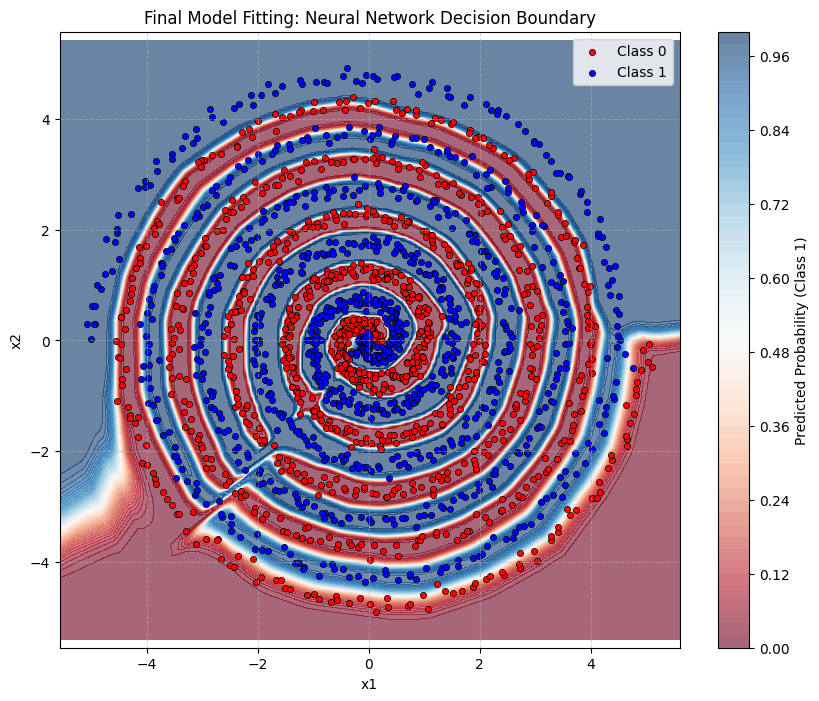

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a mesh grid to cover the feature space
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

# 2. Predict probabilities over the mesh grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
predictions = model.predict(grid_points)
Z = predictions.reshape(xx.shape)

# 3. Plot the decision boundary and original data
plt.figure(figsize=(10, 8))

# Plot the decision boundary using filled contours
contour = plt.contourf(xx, yy, Z, levels=50, cmap='RdBu', alpha=0.6)
plt.colorbar(contour, label='Predicted Probability (Class 1)')

# Plot the original dataset points
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='red', s=20, label='Class 0', edgecolors='k', linewidths=0.5)
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='blue', s=20, label='Class 1', edgecolors='k', linewidths=0.5)

plt.title('Final Model Fitting: Neural Network Decision Boundary')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.axis('equal')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()